# **Project Overview & Methodology**
## Alberta Wind Energy Site Selection & Probabilistic Risk Forecasting
---
### 1. Introduction and Background

When energy companies build wind farms, choosing the wrong location or failing to anticipate weather changes can cost millions of dollars and destabilize the power grid.

This project uses python based data analysis focused on Alberta to solve two core problems

1. **Finding the Best Location**: Using weather data to pinpoint areas where the wind is both strong and consistent (avoiding erratic/turbulent zones)
2. **Predicting Power & Risk**: Running computer simulations to forecast how much electricity a wind farm will produce tomorrow

---
### **Methodology**
This project is built using four main phases:

**Step 1: Spatiotemporal Data Collection**
We pull historical hourly weather records across a grid of key locations in alberta using Open-Meteo Historical Archive API and organize the data into a clean, unified Pandas DataFrame indexed by time and location.

**Step 2: Spatial Variance and Consistensy Analysis**
Computing long-term temporal means($\mu$) to quantify resource magnitude and standard deviations($\sigma$) or rolling gradients ($\frac{dV}{dt}$) to evaluate atmospheric turbulence

Using these the project will identify optimal geographical zones characterized by high mean wind velocities and low temporal variance, ensuring laminar predictable airflow that minimizes mechanical fatigue on turbine infrastructure

**Step 3: Stochastic Modeling & Monte Carlo Simulation**
Because windspeeds exhibit non-negative, right-skewed behaviour, velocities are modeled using the two parameter weibull distribution

$$\text{PDF}(v; A, k) = \left(\frac{k}{A}\right) \left(\frac{v}{A}\right)^{k-1} \exp\left[-\left(\frac{v}{A}\right)^k\right]$$

Where $A$ represents the scale parameter (wind magnitude) and $k$ represents the shape parameter (consistency index)

Utilizing inverse transform sampling with uniform random variables to execute thousands of Monte Carlo simulation runs, generating probabilistic synthetic weather profiles that account for atmospheric uncertainty.

**Step 4: Aerodynamic Conversion & Risk Profiling**
Power curve modelling by passing simulated wind velocity vectors $v$ through a piecewise turbine power curve function. Instead of guessing a single number, the model produces P10(pessimistic), P50(expected), and P90(optimistic) confidence envelopes. This givese energy operators a clear risk range to plan their grid schedules safely.





### **Step 1: Libraries and Spatiotemporal Data**

In [4]:
import pandas as pd
import requests
from datetime import datetime
import numpy as np
import folium
from folium.plugins import HeatMap
from scipy.interpolate import griddata
import matplotlib.pyplot as plt


print("Libraries imported successfully.")

Libraries imported successfully.


### **Generating grid**

In [69]:
# Defining expanded geographic bounding box for Alberta
lat_min, lat_max = 46.2, 60.3
lon_min, lon_max = -120.3, -109.75

resolution = 6

latPoints = np.linspace(lat_min, lat_max, resolution)
longPoints = np.linspace(lon_min, lon_max, resolution)

provincialGrid = {}
gridId = 1
for lat in latPoints:
    for long in longPoints:
        provincialGrid[f"Site_{gridId}"] = {"Latitude": round(lat, 4), "Longitude": round(long, 4)}
        gridId += 1

print(f"Generated {len(provincialGrid)} grid points across the expanded boundary.")

Generated 36 grid points across the expanded boundary.


### Setting Historical date range and looping through provincial grid and pulling hourly data from Open Meteo:

In [70]:
# Setting historical date range for full year of 2024
startDate = datetime(2024, 1, 1)
endDate = datetime(2024, 12, 31)

allLocationData = []
total_sites = len(provincialGrid)
print(f"Fetching wind data for the year {startDate.year} across {total_sites} sites...\n")

for idx, (name, coords) in enumerate(provincialGrid.items(), start=1):
    print(f"[{idx}/{total_sites}] Fetching data for {name} (Lat: {coords['Latitude']}, Lon: {coords['Longitude']})...", end="\r")
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": coords["Latitude"],
        "longitude": coords["Longitude"],
        "start_date": startDate.strftime("%Y-%m-%d"),
        "end_date": endDate.strftime("%Y-%m-%d"),
        "hourly": ["wind_speed_10m"]
    }

    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        hourly = data["hourly"]

        dfLoc = pd.DataFrame({
            "timestamp": pd.to_datetime(hourly["time"]),
            "location": name,
            "latitude": coords["Latitude"],
            "longitude": coords["Longitude"],
            "wind_speed_10m": hourly["wind_speed_10m"]
        })
        allLocationData.append(dfLoc)
    else:
        print(f"\nFailed for {name}: Status code {response.status_code}")

print("\nAll site data fetched successfully!")
masterWeatherDF = pd.concat(allLocationData, ignore_index=True)

Fetching wind data for the year 2024 across 36 sites...

[36/36] Fetching data for Site_36 (Lat: 60.3, Lon: -109.75)....
All site data fetched successfully!


### Calculating Windspeed Per site and creating contour map of windspeeds


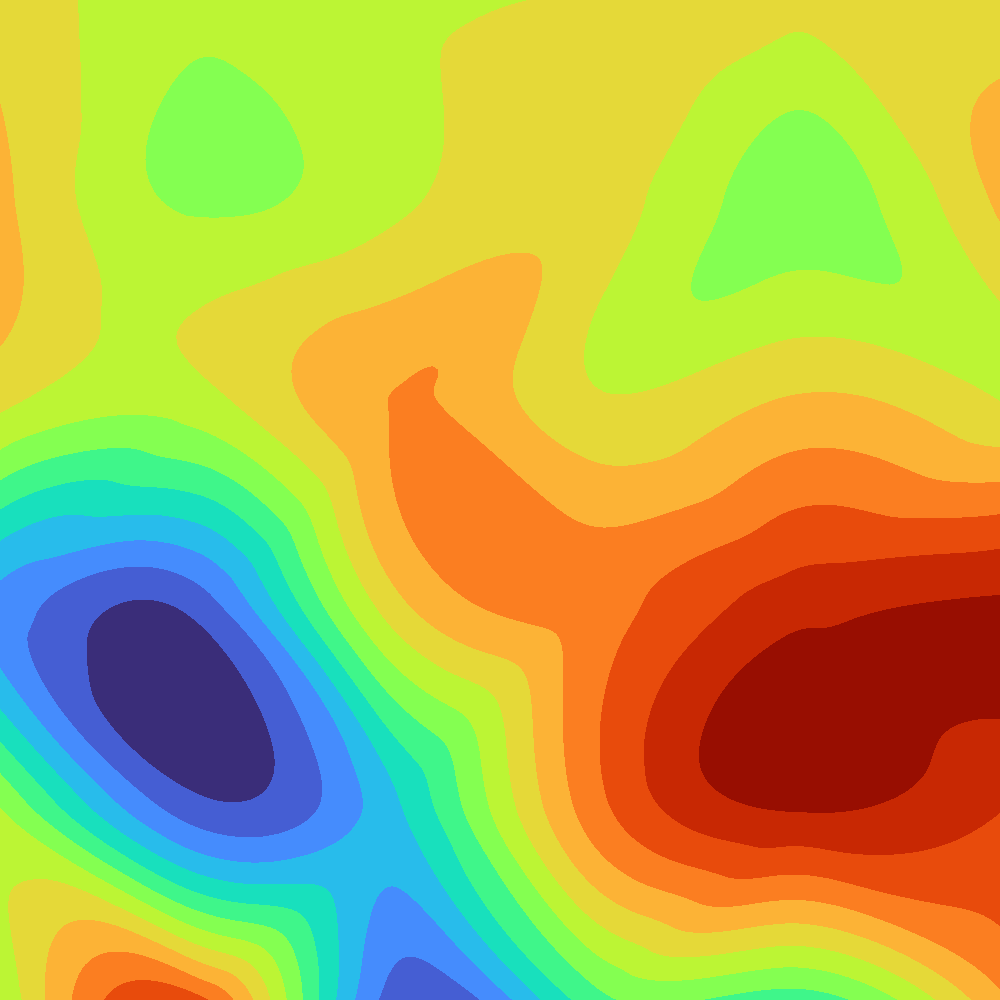

In [71]:
# 1. Group data and extract points/values
siteMeans = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_speed_10m"].mean().reset_index()
points = siteMeans[["latitude", "longitude"]].values
values = siteMeans["wind_speed_10m"].values

# 2. Setup uniform interpolation grid for all layers
gridLat = np.linspace(lat_min, lat_max, 200)
gridLong = np.linspace(lon_min, lon_max, 200)
GRIDLAT, GRIDLONG = np.meshgrid(gridLat, gridLong)

# Interpolate across the dense grid
GRIDWIND = griddata(points, values, (GRIDLAT, GRIDLONG), method='cubic')

# 3. Render and save the Contour Plot cleanly for Folium
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')

levels = np.linspace(np.nanmin(GRIDWIND), np.nanmax(GRIDWIND), 15)
contour = ax.contourf(GRIDLONG, GRIDLAT, GRIDWIND, levels=levels, cmap='turbo', extend='both')

# Save strictly the plot area with NO padding
plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
plt.margins(0, 0)
plt.savefig('wind_contour_overlay.png', transparent=True, pad_inches=0, bbox_inches='tight')
plt.close()

# 4. Place the graphic onto your Folium map overlay
contourMap = folium.Map(location=[54.0, -115.0], zoom_start=6, tiles="openstreetmap")

folium.raster_layers.ImageOverlay(
    image='wind_contour_overlay.png',
    bounds=[[lat_min, lon_min], [lat_max, lon_max]], # Alberta bounds
    opacity=0.8,
    interactive=False,
).add_to(contourMap)

display(contourMap)

---
### **Taking $\frac{dv}{dt}$ of each Loc.**
To analyze how rapidly wind conditions change over time vs where they remain steady, we can compute the discrete temporal first derivative($\frac{dv}{dt}$) for each location's hourly time series.

In code, this means taking the hourly difference of the wind speeds by aggregating the mean absolute rate of change for each site, we can map out the most volatile, rapidly fluctuating zones versus the most meteorologically stable areas across Alberta


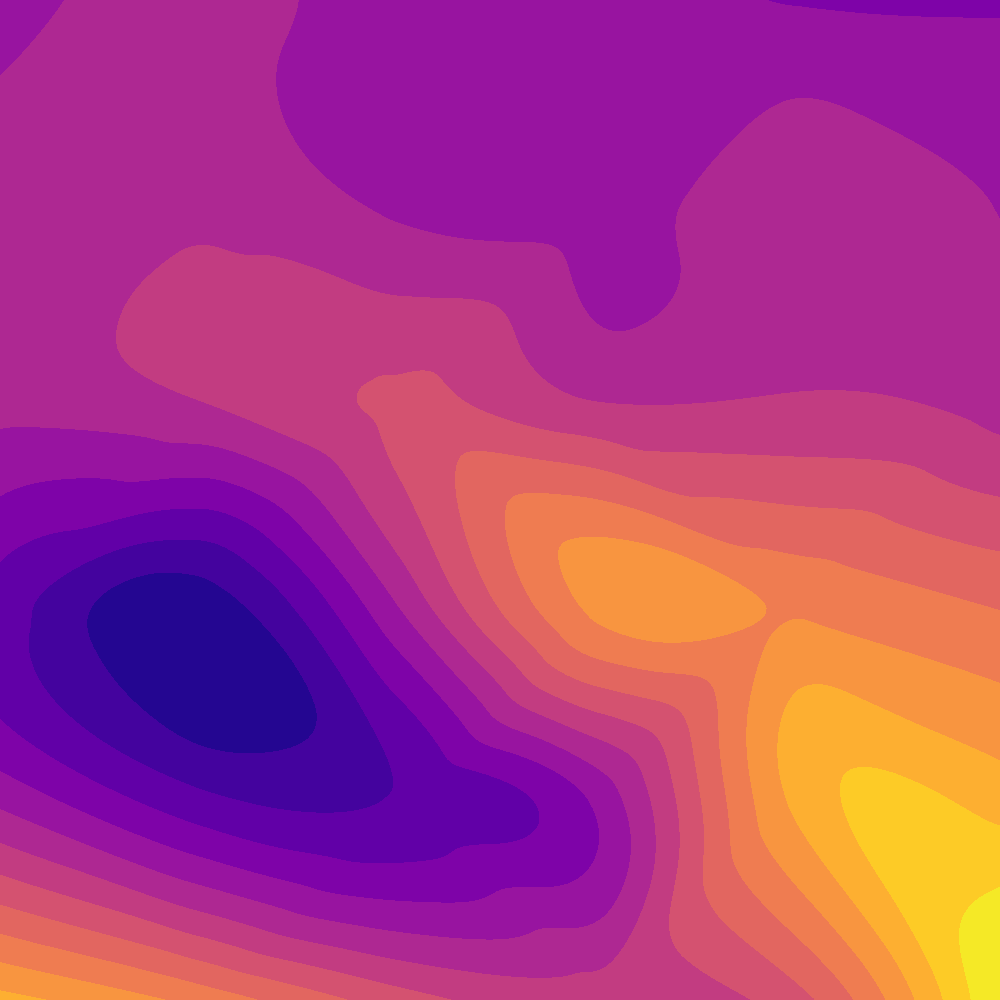

In [72]:
# 1. Calculate rate of change
masterWeatherDF = masterWeatherDF.sort_values(["location","timestamp"])
masterWeatherDF["wind_derivative"] = masterWeatherDF.groupby("location")["wind_speed_10m"].diff().abs()

siteChange = masterWeatherDF.groupby(["location", "latitude", "longitude"])["wind_derivative"].mean().reset_index()

points = siteChange[["latitude", "longitude"]].values
values = siteChange["wind_derivative"].values

# 2. Interpolate the derivative metric across the same spatial grid
GRID_CHANGE = griddata(points, values, (GRIDLAT, GRIDLONG), method='cubic')

# 3. Render and save the Contour Plot cleanly
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')

levels = np.linspace(np.nanmin(GRID_CHANGE), np.nanmax(GRID_CHANGE), 15)
contour = ax.contourf(GRIDLONG, GRIDLAT, GRID_CHANGE, levels=levels, cmap='plasma', extend='both')

# Save strictly the plot area with NO padding
plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
plt.margins(0, 0)
plt.savefig('wind_derivative_contour.png', transparent=True, pad_inches=0, bbox_inches='tight')
plt.close()

# 4. Overlay onto your Folium map
derivativeMap = folium.Map(location=[54.0, -115.0], zoom_start=6, tiles="openstreetmap")

folium.raster_layers.ImageOverlay(
    image='wind_derivative_contour.png',
    bounds=[[lat_min, lon_min], [lat_max, lon_max]], # Alberta bounds
    opacity=0.8,
    interactive=False,
).add_to(derivativeMap)

display(derivativeMap)

---
### **Finding the "Sweet Spot"**
To find ideal zones where high wind speeds overlap with low volatility (stable, consistent flow over time), we can combine both spatial grids into a Multi-Criteria Sweet-Spot Index.Mathematically, we normalize both the mean wind speed grid (GRIDWIND) and the volatility grid (GRID_CHANGE) to a $0\text{–}1$ scale, and compute a balance score:$$\text{Sweet-Spot Score} = \text{Normalized Wind Speed} - \text{Normalized Volatility}$$This rewards locations with strong winds while heavily penalizing erratic, highly turbulent weather patterns.

Top 5 Optimal Wind Farm Sweet-Spot Sites in Alberta:


,location,latitude,longitude,wind_speed_10m,wind_derivative,sweet_spot_score
1,Site_10,49.02,-113.97,12.445264,1.199055,0.514625
9,Site_18,51.84,-109.75,14.285849,1.687647,0.365573
28,Site_35,60.30,-111.86,10.426810,1.160036,0.336912
23,Site_30,57.48,-109.75,11.146129,1.268314,0.335434
29,Site_36,60.30,-109.75,10.287010,1.154719,0.326400



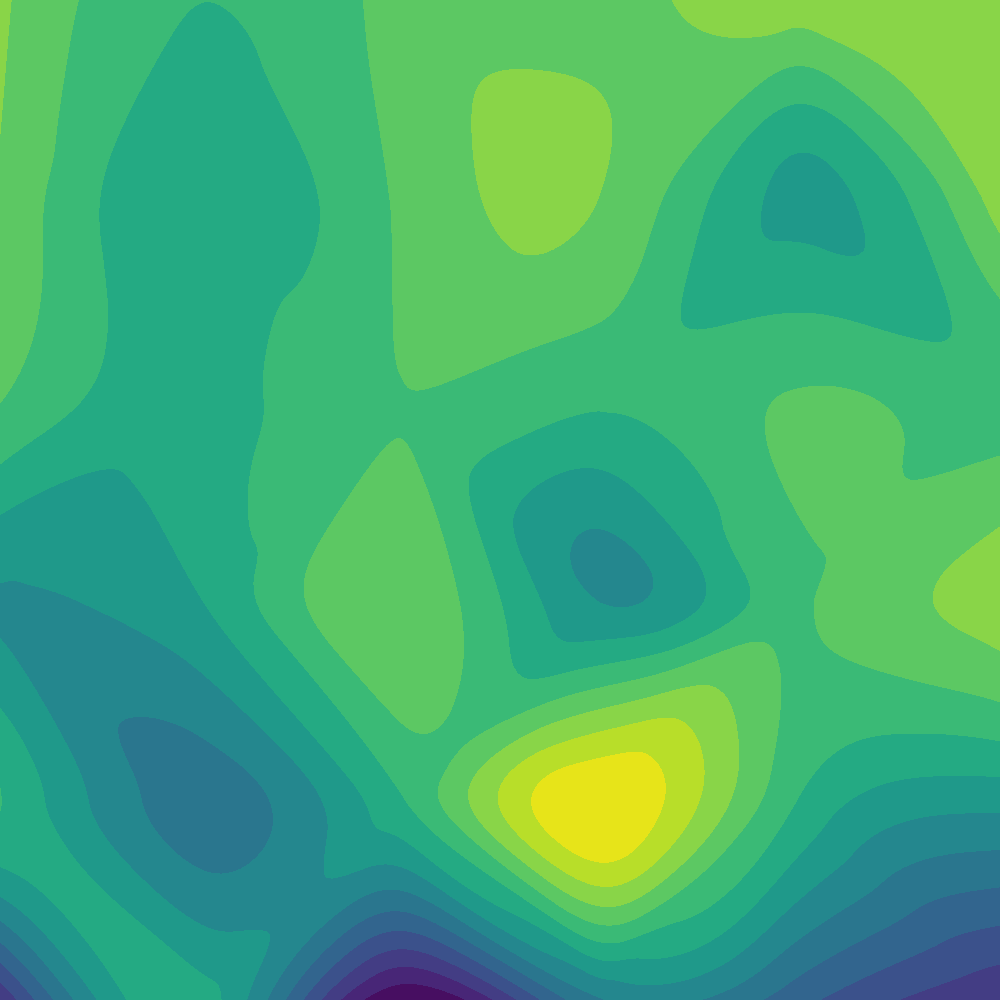

In [73]:
# 1. Compute site-level combined metrics
site_combined = pd.merge(siteMeans, siteChange, on=["location", "latitude", "longitude"])

# Normalize metrics for scoring
s_min, s_max = site_combined["wind_speed_10m"].min(), site_combined["wind_speed_10m"].max()
d_min, d_max = site_combined["wind_derivative"].min(), site_combined["wind_derivative"].max()

norm_speed = (site_combined["wind_speed_10m"] - s_min) / (s_max - s_min + 1e-5)
norm_deriv = (site_combined["wind_derivative"] - d_min) / (d_max - d_min + 1e-5)

# Higher score = Strong winds + Low volatility (Stable & Fast)
site_combined["sweet_spot_score"] = norm_speed - norm_deriv

print("Top 5 Optimal Wind Farm Sweet-Spot Sites in Alberta:")
display(site_combined.sort_values(by="sweet_spot_score", ascending=False).head(5))

# 2. Compute the Grid-level Sweet-Spot Surface across the 200x200 mesh
norm_grid_wind = (GRIDWIND - np.nanmin(GRIDWIND)) / (np.nanmax(GRIDWIND) - np.nanmin(GRIDWIND) + 1e-5)
norm_grid_change = (GRID_CHANGE - np.nanmin(GRID_CHANGE)) / (np.nanmax(GRID_CHANGE) - np.nanmin(GRID_CHANGE) + 1e-5)

GRID_SWEETSPOT = norm_grid_wind - norm_grid_change

# 3. Render and save the Contour Plot cleanly
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')

levels = np.linspace(np.nanmin(GRID_SWEETSPOT), np.nanmax(GRID_SWEETSPOT), 15)
contour = ax.contourf(GRIDLONG, GRIDLAT, GRID_SWEETSPOT, levels=levels, cmap='viridis', extend='both')

plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
plt.margins(0, 0)
plt.savefig('wind_sweetspot_contour.png', transparent=True, pad_inches=0, bbox_inches='tight')
plt.close()

# 4. Overlay onto a new Folium map
sweetSpotMap = folium.Map(location=[54.0, -115.0], zoom_start=6, tiles="openstreetmap")

folium.raster_layers.ImageOverlay(
    image='wind_sweetspot_contour.png',
    bounds=[[lat_min, lon_min], [lat_max, lon_max]], # Alberta bounds
    opacity=0.8,
    interactive=False,
).add_to(sweetSpotMap)

display(sweetSpotMap)